In [1]:
from rdkit import Chem
import os
from rdkit.Chem.Draw import IPythonConsole
ptable = Chem.GetPeriodicTable()
electronegativity_dict = {1: 2.2,
 3: 0.98,
 4: 1.57,
 5: 2.04,
 6: 2.55,
 7: 3.04,
 8: 3.44,
 9: 3.98,
 11: 0.93,
 12: 1.31,
 13: 1.61,
 14: 1.9,
 15: 2.19,
 16: 2.58,
 17: 3.16,
 19: 0.82,
 20: 1.0,
 21: 1.36,
 22: 1.54,
 23: 1.63,
 24: 1.66,
 25: 1.55,
 26: 1.83,
 27: 1.88,
 28: 1.91,
 29: 1.9,
 30: 1.65,
 31: 1.81,
 32: 2.01,
 33: 2.18,
 34: 2.55,
 35: 2.96,
 36: 3.0,
 37: 0.82,
 38: 0.95,
 39: 1.22,
 40: 1.33,
 41: 1.6,
 42: 2.16,
 43: 1.9,
 44: 2.2,
 45: 2.28,
 46: 2.2,
 47: 1.93,
 48: 1.69,
 49: 1.78,
 50: 1.96,
 51: 2.05,
 52: 2.1,
 53: 2.66}


In [2]:
"""
Rule 1: Identify pi and pi* and lone pair and empty orbital as source and sinks
Rule 2: Identify suitable leaving groups (suitable sigma star)
Rule 2.5: Identify reactive sigma bonds
Rule 3: Identify acidic hydrogens
"""

'\nRule 1: Identify pi and pi* and lone pair and empty orbital as source and sinks\nRule 2: Identify suitable leaving groups (suitable sigma star)\nRule 2.5: Identify reactive sigma bonds\nRule 3: Identify acidic hydrogens\n'

In [3]:
cat_and_brom = Chem.MolFromSmiles(r'C[C+](C)C.[Br-]')
tert_brom = Chem.MolFromSmiles('CC(C)(Br)C')

In [4]:
def identify_source(mol, rules = "all"):
    for atom in mol.GetAtoms():
        # Look for hydrides - M-H bond
        if electronegativity_dict[atom.GetAtomicNum()] < 2.05 and atom.GetFormalCharge() < 0 and atom.GetNumExplicitHs() > 0:
            atom.SetProp('source', 'hydride')
        valence_electrons = ptable.GetNOuterElecs(atom.GetAtomicNum())
        lone_electrons = valence_electrons - atom.GetTotalValence() - atom.GetFormalCharge()
        if lone_electrons > 0:
            atom.SetProp('source', 'lone pair')
            
    for bond in mol.GetBonds():
        if bond.GetEndAtom().HasProp('source') or bond.GetBeginAtom().HasProp('source'):
            continue
        # Conditional on rules being on
        if rules == 'all':
            if bond.GetBondTypeAsDouble() == 1:
                # For any element less electronegative than boron (inclusive) - add sigma bond as source - going from more electronegative atom
                if electronegativity_dict[bond.GetBeginAtom().GetAtomicNum()] < 2.05:
                    #bond.GetEndAtom().SetProp('source', 'sigma bond')
                    bond.SetProp('source', 'sigma bond')
                    bond.SetProp('source_bond_atom', str(bond.GetEndAtom().GetIdx()))
                    bond.SetProp('source_other_atom', str(bond.GetBeginAtom().GetIdx()))
                if electronegativity_dict[bond.GetEndAtom().GetAtomicNum()] < 2.05:
                    #bond.GetBeginAtom().SetProp('source', 'sigma bond')
                    bond.SetProp('source', 'sigma bond')
                    bond.SetProp('source_bond_atom', str(bond.GetBeginAtom().GetIdx()))
                    bond.SetProp('source_other_atom', str(bond.GetEndAtom().GetIdx()))
        # Looking for double and triple bonds - ignoring aromatic systems
        if bond.GetBondTypeAsDouble() > 1.5:
            bond.SetProp('source', 'pi bond')
            atom1 = bond.GetBeginAtom()
            atom2 = bond.GetEndAtom()
            # if bond is homonuclear then either atom can be source
            if atom1.GetAtomicNum() == atom2.GetAtomicNum():
                #atom1.SetProp('source', 'pi bond')
                #atom2.SetProp('source', 'pi bond')
                bond.SetProp('source_bond_atom', 'both')
                bond.SetProp('source_other_atom', 'both')
            else:
                # if bond is heteronuclear then the more electronegative atom is source
                if electronegativity_dict[atom1.GetAtomicNum()] < electronegativity_dict[atom2.GetAtomicNum()]:
                    bond.SetProp('source_bond_atom', str(atom2.GetIdx()))
                    bond.SetProp('source_other_atom', str(atom1.GetIdx()))
                else:
                    bond.SetProp('source_bond_atom', str(atom1.GetIdx()))
                    bond.SetProp('source_other_atom', str(atom2.GetIdx()))
    # This loop coming after the bond loop ensures that all molecules with lone pairs react via the lone pair instead of a pi bond
    
        
        

In [5]:
def identify_sink(mol, rules = "all"):
    for atom in mol.GetAtoms():
        valence_electrons = ptable.GetNOuterElecs(atom.GetAtomicNum())
        lone_electrons = valence_electrons - atom.GetTotalValence() - atom.GetFormalCharge()
        num_bond_electrons = atom.GetTotalValence()*2
        # this may only be valid for the first few rows of the periodic table
        if lone_electrons + num_bond_electrons < 8 and valence_electrons > 2:
            atom.SetProp('sink', 'empty AO')
        #Special case for H not needed any more I think?
        if atom.GetAtomicNum() == 1 and lone_electrons + num_bond_electrons < 2:
            atom.SetProp('sink', 'empty AO')

    for bond in mol.GetBonds():
        if bond.GetEndAtom().HasProp('sink') or bond.GetBeginAtom().HasProp('sink'):
            continue
        # Conditional on all rules being swtiched on
        if rules == "all":
            # Identify possible sigma stars by considering leaving groups being any element that has a higher electronegativity than carbon
            if bond.GetBondTypeAsDouble() == 1:
                if electronegativity_dict[bond.GetEndAtom().GetAtomicNum()] > 2.55:
                    bond.SetProp('sink', 'sigma star')
                    #Set the other atom connected to this leaving group as the electron sink
                    #bond.GetBeginAtom().SetProp('sink', 'sigma star')
                    bond.SetProp('sink_bond_atom', str(bond.GetBeginAtom().GetIdx()))
                    bond.SetProp('sink_other_atom', str(bond.GetEndAtom().GetIdx()))
                # Repeat for the other atom in a bond. Note e.g. N-N would be possible to attack at each end
                if electronegativity_dict[bond.GetBeginAtom().GetAtomicNum()] > 2.55:
                    bond.SetProp('sink', 'sigma star')
                    #bond.GetEndAtom().SetProp('sink', 'sigma star')
                    #bond.GetEndAtom().SetProp('sink', 'sigma star')
                    bond.SetProp('sink_bond_atom', str(bond.GetEndAtom().GetIdx()))
                    bond.SetProp('sink_other_atom', str(bond.GetBeginAtom().GetIdx()))
        if bond.GetBondTypeAsDouble() > 1.5:
            bond.SetProp('sink', 'pi star')
            atom1 = bond.GetBeginAtom()
            atom2 = bond.GetEndAtom()
            if atom1.GetAtomicNum() == atom2.GetAtomicNum():
                #atom1.SetProp('sink', 'pi star')
                #atom2.SetProp('sink', 'pi star')
                bond.SetProp('sink_bond_atom', 'both')
                bond.SetProp('sink_other_atom', 'both')
            else:
                if electronegativity_dict[atom1.GetAtomicNum()] > electronegativity_dict[atom2.GetAtomicNum()]:
                    bond.SetProp('sink_bond_atom', str(atom2.GetIdx()))
                    bond.SetProp('sink_other_atom', str(atom1.GetIdx()))
                else:
                    #atom1.SetProp('sink', 'pi star')
                    bond.SetProp('sink_bond_atom', str(atom1.GetIdx()))
                    bond.SetProp('sink_other_atom', str(atom2.GetIdx()))
    # Likewise as above, this loop coming second ensures that empty orbitals are attacked in place of a pi star where an atom might have both
    

In [6]:
def prepare_molecule(mol):
    identify_sink(mol)
    identify_source(mol)
    return None

In [7]:
acetophenone = Chem.MolFromSmiles('CC(=O)C1=CC=CC=C1')
cyanide = Chem.MolFromSmiles('[C-]#N')
ethylbromide = Chem.MolFromSmiles('CCBr')
iodide = Chem.MolFromSmiles('[I-]')

In [8]:
identify_sink(cyanide)
identify_source(cyanide)
identify_sink(ethylbromide)
identify_source(acetophenone)

In [9]:
def b_to_a(mol, i, j):
    bond = mol.GetBondBetweenAtoms(i,j)
    bond_order = int(bond.GetBondTypeAsDouble())
    a_l = mol.GetAtomWithIdx(i)
    c = a_l.GetFormalCharge()
    a_l.SetFormalCharge(c+1)
    a_b = mol.GetAtomWithIdx(j)
    c = a_b.GetFormalCharge()
    a_b.SetFormalCharge(c-1)
    e_mol = Chem.EditableMol(mol)
    e_mol.RemoveBond(i,j)
    if bond_order != 1:
        e_mol.AddBond(i,j, order=Chem.BondType.values[bond_order-1])
    return e_mol.GetMol()

def a_to_b(mol, i, j):
    bond = mol.GetBondBetweenAtoms(i,j)
    a_l = mol.GetAtomWithIdx(i)
    c = a_l.GetFormalCharge()
    a_l.SetFormalCharge(c+1)
    a_b = mol.GetAtomWithIdx(j)
    c = a_b.GetFormalCharge()
    a_b.SetFormalCharge(c-1)
    e_mol = Chem.EditableMol(mol)
    if not bond:
        e_mol.AddBond(i,j, order=Chem.BondType.values[1])
    else:
        e_mol.RemoveBond(i,j)
        bond_order = int(bond.GetBondTypeAsDouble())
        e_mol.AddBond(i,j, order=Chem.BondType.values[bond_order+1])
    return e_mol.GetMol()

In [10]:
def clean_mol(list_mol):
    existing_inchi = set([])
    clean_list = []
    for mol in list_mol:
        inchi = Chem.MolToInchi(mol)
        if inchi not in existing_inchi:
            existing_inchi.add(inchi)
            clean_list.append(mol)
    return clean_list

In [13]:
mol2 = Chem.MolFromSmiles('CC1CO1')
mol1 = Chem.MolFromSmiles('CC[Mg]Br')
prepare_molecule(mol1)
prepare_molecule(mol2)
new_mols = []
connected_mols = []
atoms = [a for a in mol1.GetAtoms()] + [a for a in mol2.GetAtoms()]
bonds = [b for b in mol1.GetBonds()] + [b for b in mol2.GetBonds()]
for atom1 in atoms:
    loop_number = 0

    if loop_number == 1:
        loop_number = 2
        source_type = atom1.GetProp('source')
        atom1.ClearProp('source')
        atom1.SetProp('sink', sink_type)

    elif atom1.HasProp('source') and atom1.HasProp('sink'):
        loop_number = 1
        sink_type = atom1.GetProp('sink')
        atom1.ClearProp('sink')
    
    while loop_number < 3:
        print(loop_number)

    #check if the source is a bond, to avoid errors when removing the 'make_bond' property
        bond_flag = False
        reinstate_sink = {}
        reinstate_atom_1 = False
        if atom1.HasProp('source'):
            print(atom1.GetIdx(), atom1.GetSymbol(), atom1.GetTotalValence(), atom1.GetProp('source'))            
            if atom1.GetProp('source') == 'lone pair' or atom1.GetProp('source') == 'hydride':
                atom1.SetBoolProp('make_bond', 1)
            """ if atom1.GetProp('source') == 'sigma bond' or atom1.GetProp('source') == 'pi bond':
                bond_flag = True
                if atom1.HasProp('sink'):
                    reinstate_atom_1 = atom1.GetProp('sink')
                    atom1.ClearProp('sink')
                atom1.SetBoolProp('make_bond', 1)
                for bond1 in atom1.GetBonds():
                    if bond1.HasProp('source'):
                        partner_atom = bond1.GetOtherAtom(atom1)
                        #An ugly workaround where having two source bonds means only a bond that can actually be a source on the right atom is used
                        if electronegativity_dict[atom1.GetAtomicNum()] < electronegativity_dict[partner_atom.GetAtomicNum()]:
                            continue
                        if bond1.HasProp('sink'):
                            reinstate_sink[bond1.GetIdx()] = bond1.GetProp('sink')
                            bond1.ClearProp('sink')           
                        bond1.SetBoolProp('make_bond', 1) """
                        #Technically there could be more than one reactive sigma bond attached to each atom; this might be implemented later
            for atom2 in atoms:
                if atom1.GetIdx() == atom2.GetIdx():
                    continue
                #reinstate_source = {}
                #reinstate_atom_2 = False
                if atom2.HasProp('sink'):
                    print(atom2.GetIdx(), atom2.GetSymbol(), atom2.GetTotalValence(), atom2.GetProp('sink'))
                    if atom2.GetProp('sink') == 'empty AO':
                        atom2.SetBoolProp('make_bond', 1)
                        new_mols.append(Chem.CombineMols(mol1, mol2))
                    """ elif atom2.GetProp('sink') == 'pi star' or atom2.GetProp('sink') == 'sigma star':
                        atom2.SetBoolProp('make_bond', 1)
                        if atom2.HasProp('source'):
                            reinstate_atom_2 = atom2.GetProp('source')
                            #print('reinstante source', atom2.GetSymbol(), atom2.GetProp('source'))
                            atom2.ClearProp('source')
                        for bond2 in atom2.GetBonds():
                            if bond2.HasProp('sink'):
                                partner_atom = bond2.GetOtherAtom(atom2)
                                #An ugly workaround where having two sink bonds means only a bond that can actually be a sink on the right atom is used
                                if electronegativity_dict[atom2.GetAtomicNum()] > electronegativity_dict[partner_atom.GetAtomicNum()]:
                                    continue
                                if bond2.HasProp('source'):
                                    reinstate_source[bond2.GetIdx()] = bond2.GetProp('source')
                                    bond2.ClearProp('source')
                                bond2.SetBoolProp('make_bond', 1)
                                new_mols.append(Chem.CombineMols(mol1, mol2))
                                bond2.ClearProp('make_bond') """
                    atom2.ClearProp('make_bond')
            for bond2 in bonds:
                if bond2.HasProp('sink'):
                    print('sink', bond2.GetProp('sink'))
                    bond2.SetBoolProp('make_bond', 1)
                    a1 = bond2.GetBeginAtom()
                    a2 = bond2.GetEndAtom()
                    print('sink', bond2.GetProp('sink_bond_atom'))
                    #print('other', bond2.GetProp('other_bond_atom'))
                    print(a1.GetSymbol(), a1.GetIdx(), a2.GetSymbol(), a2.GetIdx())
                    if bond2.GetProp('sink_bond_atom') == 'both':
                        a1.SetBoolProp('make_bond', 1)
                        a2.SetBoolProp('other_atom', 1)
                        new_mols.append(Chem.CombineMols(mol1, mol2))
                        a1.ClearProp('make_bond')
                        a2.ClearProp('other_atom')
                        a2.SetBoolProp('make_bond', 1)
                        a1.SetBoolProp('other_atom', 1)
                        new_mols.append(Chem.CombineMols(mol1, mol2))
                        a2.ClearProp('make_bond')
                        a1.ClearProp('other_atom')
                    if bond2.GetProp('sink_bond_atom') == str(a1.GetIdx()):
                        a1.SetBoolProp('make_bond', 1)
                        a2.SetBoolProp('other_atom', 1)
                        print('make_bond', a1.GetSymbol())
                        print('other_atom', a2.GetSymbol())
                        new_mols.append(Chem.CombineMols(mol1, mol2))
                        a1.ClearProp('make_bond')
                        a2.ClearProp('other_atom')
                    elif bond2.GetProp('sink_bond_atom') == str(a2.GetIdx()):
                        a2.SetBoolProp('make_bond', 1)
                        a1.SetBoolProp('other_atom', 1)
                        print('make_bond', a2.GetSymbol())
                        print('other_atom', a1.GetSymbol())
                        new_mols.append(Chem.CombineMols(mol1, mol2))
                        a1.ClearProp('other_atom')
                        a2.ClearProp('make_bond')
                    bond2.ClearProp('make_bond')
        

                """ if reinstate_source:
                    print(reinstate_source)
                    for idx, bond_type in reinstate_source.items():
                        for bond in atom2.GetBonds():
                            if bond.GetIdx() == idx:
                                print(idx)
                                bond.SetProp('source', bond_type) 
                                print('reinstating source', bond.GetBeginAtomIdx(), bond.GetEndAtomIdx(), bond.GetProp('source'))
                if reinstate_atom_2:
                    #print('reinstanting')
                    atom2.SetProp('source', reinstate_atom_2)    """                     
            atom1.ClearProp('make_bond')
        if loop_number == 2:
            atom1.SetProp('source', source_type)
            break
        if loop_number == 0:
            print('here')
            break


        """  # Only remove property if bond1 was defined in the first place
        if bond_flag:
            bond1.ClearProp('make_bond')
        if reinstate_sink:
            for idx, bond_type in reinstate_sink.items():
                    for bond in atom1.GetBonds():
                        if bond.GetIdx() == idx:
                            bond.SetProp('sink', bond_type)
                            print('reinstante sink',bond.GetBeginAtomIdx(), bond.GetEndAtomIdx(), bond.GetProp('sink'))
        if reinstate_atom_1:
            atom1.SetProp('sink', reinstate_atom_1)
 """
        




for bond1 in bonds:
    print('do we get to the bond loop?')
    """ loop_number = 0
    if loop_number == 1:
        loop_number = 2
        source_type = bond1.GetProp('source')
        bond1.ClearProp('source')
        bond1.SetProp('sink', sink_type)

    elif bond1.HasProp('source') and bond1.HasProp('sink'):
        loop_number = 1
        sink_type = bond1.GetProp('sink')
        bond1.ClearProp('sink')
    
    while loop_number < 3: """
    labelled_sources =[]
    if bond1.HasProp('source'):
        print('source', bond1.GetProp('source'))
        bond1.SetBoolProp('make_bond', 1)
        a1 = bond1.GetBeginAtom()
        a2 = bond1.GetEndAtom()
        print(bond1.GetProp('source'))
        if bond1.GetProp('source_bond_atom') == 'both':
            a1.SetBoolProp('make_bond', 1)
            a2.SetBoolProp('other_atom', 1)
            new_mols.append(Chem.CombineMols(mol1, mol2))
            a1.ClearProp('make_bond')
            a2.ClearProp('other_atom')
            a2.SetBoolProp('make_bond', 1)
            a1.SetBoolProp('other_atom', 1)
            new_mols.append(Chem.CombineMols(mol1, mol2))
            a2.ClearProp('make_bond')
        if bond1.GetProp('source_bond_atom') == a1.GetIdx():
            a1.SetBoolProp('make_bond', 1)
            a2.SetBoolProp('other_atom', 1)
            new_mols.append(Chem.CombineMols(mol1, mol2))
            a1.ClearProp('make_bond')
            a2.ClearProp('other_atom')
        elif bond1.GetProp('source_bond_atom') == a2.GetIdx():
            a2.SetBoolProp('make_bond', 1)
            a1.SetBoolProp('other_atom', 1)
            new_mols.append(Chem.CombineMols(mol1, mol2))
            a1.ClearProp('other_atom')
            a2.ClearProp('make_bond')
        print('check', a1.GetSymbol(), a2.GetSymbol())
        bond1.ClearProp('make_bond')
            
        for atom2 in atoms:
            if atom2.HasProp('sink'):
                print(atom2.GetIdx(), atom2.GetSymbol(), atom2.GetTotalValence(), atom2.GetProp('sink'))
                atom2.SetBoolProp('make_bond', 1)
                new_mols.append(Chem.CombineMols(mol1, mol2))
                atom2.ClearProp('make_bond')
        for bond2 in bonds:
            if bond2.GetIdx() == bond1.GetIdx():
                continue
            if bond2.HasProp('sink'):
                bond2.SetBoolProp('make_bond', 1)
                a1 = bond2.GetBeginAtom()
                a2 = bond2.GetEndAtom()
                if bond2.GetProp('sink_bond_atom') == 'both':
                    a1.SetBoolProp('make_bond', 1)
                    a2.SetBoolProp('other_atom', 1)
                    new_mols.append(Chem.CombineMols(mol1, mol2))
                    a1.ClearProp('make_bond')
                    a2.ClearProp('other_atom')
                    a2.SetBoolProp('make_bond', 1)
                    a1.SetBoolProp('other_atom', 1)
                    new_mols.append(Chem.CombineMols(mol1, mol2))
                    a2.ClearProp('make_bond')
                    a1.ClearProp('other_atom')
                if bond2.GetProp('sink_bond_atom') == a1.GetIdx():
                    a1.SetBoolProp('make_bond', 1)
                    a2.SetBoolProp('other_atom', 1)
                    new_mols.append(Chem.CombineMols(mol1, mol2))
                    a1.ClearProp('make_bond')
                    a2.ClearProp('other_atom')
                elif bond2.GetProp('sink_bond_atom') == a2.GetIdx():
                    a2.SetBoolProp('make_bond', 1)
                    a1.SetBoolProp('other_atom', 1)
                    new_mols.append(Chem.CombineMols(mol1, mol2))
                    a1.ClearProp('other_atom')
                    a2.ClearProp('make_bond')
                bond2.ClearProp('make_bond')
    """ if loop_number == 2:
        bond1.SetProp('source', source_type)
        break
    if loop_number == 0:
        break """

counter = 0


0
here
0
here
0
here
0
3 Br 1 lone pair
sink sigma star
sink 2
Mg 2 Br 3
make_bond Mg
other_atom Br
sink sigma star
sink 2
C 2 O 3
make_bond C
other_atom O
sink sigma star
sink 1
O 3 C 1
make_bond C
other_atom O
here
0
here
0
here
0
here
0
3 O 2 lone pair
sink sigma star
sink 2
Mg 2 Br 3
make_bond Mg
other_atom Br
sink sigma star
sink 2
C 2 O 3
make_bond C
other_atom O
sink sigma star
sink 1
O 3 C 1
make_bond C
other_atom O
here
do we get to the bond loop?
do we get to the bond loop?
source sigma bond
sigma bond
check C Mg
do we get to the bond loop?
do we get to the bond loop?
do we get to the bond loop?
do we get to the bond loop?
do we get to the bond loop?


In [12]:
for mol in new_mols:
    print('do we get here?')
    inter_mol = mol
    k = None
    l = None
    # Need to treat hydrides differently because of the way RDKit handles them
    hydride_flag = False
    bond_sink_flag = False
    flag_save = False

    for atom in mol.GetAtoms():
        if atom.HasProp('make_bond'):
            if atom.HasProp('source'):
                print('source connecting loop', atom.GetSymbol(), atom.GetProp('source'))
                i = atom.GetIdx()
                # Different behaviour required for hydrides
                if atom.GetProp('source') == 'hydride':
                    hydride_flag = True
                    #Debug statement
                    #print(atom.GetSymbol(),atom.GetNumExplicitHs(), atom.GetNumImplicitHs())
                    atom.SetNumExplicitHs(atom.GetNumExplicitHs() - 1)
                    atom.SetFormalCharge(atom.GetFormalCharge() + 1)
            elif atom.HasProp('sink'):
                print('sink connecting loop', atom.GetSymbol(), atom.GetProp('sink'))
                j = atom.GetIdx()
            else:
                for bond in atom.GetBonds():
                    if bond.HasProp('make_bond'):
                        if bond.HasProp('source'):
                            print('source',bond.GetProp('source'))
                            for a in [bond.GetBeginAtom(), bond.GetEndAtom()]:
                                if a.HasProp('make_bond'):
                                    i = a.GetIdx()
                                if a.HasProp('other_atom'):
                                    k = a.GetIdx()
                            print('i', inter_mol.GetAtomWithIdx(i).GetSymbol())
                            print('k', inter_mol.GetAtomWithIdx(k).GetSymbol())
                            inter_mol = b_to_a(inter_mol, k, i)
                        if bond.HasProp('sink'):
                            print('sink',bond.GetProp('sink'), bond.GetBeginAtom().GetSymbol(), bond.GetEndAtom().GetSymbol())
                            for a in [bond.GetBeginAtom(), bond.GetEndAtom()]:
                                if a.HasProp('make_bond'):
                                    j = a.GetIdx()
                                if a.HasProp('other_atom'):
                                    l = a.GetIdx()
                            print('j', inter_mol.GetAtomWithIdx(j).GetSymbol())
                            print('l', inter_mol.GetAtomWithIdx(l).GetSymbol())
                            inter_mol = b_to_a(inter_mol, j, l)
                            #Debug statement
                            #print('source', atom.GetSymbol(), atom.GetIdx(), atom.GetProp('source'))
                            #Debug statement
                            #print('sink', atom.GetSymbol(), atom.GetIdx(), atom.GetProp('sink'))
                            #Debug statement
                            #print(bond.GetBeginAtom().GetSymbol(), bond.GetEndAtom().GetSymbol(), bond.GetBondTypeAsDouble())
                """ if atom.GetProp('source') == 'sigma bond' or atom.GetProp('source') == 'pi bond':
                    print('breaking bond here')
                    for bond in atom.GetBonds():
                        if bond.HasProp('make_bond') and bond.HasProp('source') and bond.GetProp('source') == atom.GetProp('source'):
                            k = bond.GetOtherAtom(atom).GetIdx()
                            inter_mol = b_to_a(inter_mol, k, i) """
           
    """ 
    for bond in mol.GetBonds():
        if bond.HasProp('make_bond'):
            if bond.HasProp('source') and bond.HasProp('sink'):
                    #This needs a special case to deal with
            if bond.HasProp('source'):
                i = bond.GetProp('source_bond_atom')


                if atom.GetProp('sink') == 'sigma star' or atom.GetProp('sink') == 'pi star':
                    print('sink', atom.GetSymbol(), atom.GetIdx(), atom.GetProp('sink'))
                    #Debug statement
                    #if atom.GetProp('sink') == 'sigma star':
                        #for bond in atom.GetBonds():
                            #print('bonds connected to sigma star', bond.HasProp('make_bond'), bond.GetBeginAtom().GetSymbol(), bond.GetEndAtom().GetSymbol())
                            #if bond.HasProp('make_bond'):
                              #  l = bond.GetOtherAtom(atom).GetIdx()
                               # inter_mol = a_to_b(inter_mol, j, l)
                    bond_sink_flag = True
                    for bond in atom.GetBonds():
                        print(bond.GetBeginAtom().GetSymbol(), bond.GetEndAtom().GetSymbol(), bond.GetBondTypeAsDouble())
                        if bond.HasProp('make_bond') and bond.HasProp('sink') and bond.GetProp('sink') == atom.GetProp('sink'):
                            l = bond.GetOtherAtom(atom).GetIdx()
                            print('breaking bond between', atom.GetSymbol(),atom.GetIdx(), bond.GetOtherAtom(atom).GetSymbol(), bond.GetOtherAtom(atom).GetIdx())   
                            inter_mol = b_to_a(inter_mol, j, l)
                            flag_save = True
            else:
                print('something went wrong') """
    if (k is not None and k == j) or (l is not None and l == i) or i == j or (bond_sink_flag and not flag_save):
        # this is will remove any 'cycles' that close in on themselves and make no net change
        continue
    if hydride_flag:
        inter_mol.GetAtomWithIdx(j).SetNumExplicitHs(inter_mol.GetAtomWithIdx(j).GetNumImplicitHs() + 1)
        inter_mol.GetAtomWithIdx(j).SetFormalCharge(inter_mol.GetAtomWithIdx(j).GetFormalCharge() - 1)
        connected_mols.append(inter_mol)
        continue
    print('making bond between', inter_mol.GetAtomWithIdx(i).GetSymbol(), i, inter_mol.GetAtomWithIdx(j).GetSymbol(), j)
    inter_mol = a_to_b(inter_mol, i, j)
    connected_mols.append(inter_mol)
    counter +=1
    print(counter, ":", Chem.MolToSmiles(inter_mol))
    
# as it stands this doesn't work for Grignards because of the way that InChI is generated
connected_mols = clean_mol(connected_mols)
    


do we get here?
sink sigma star Mg Br
j Br
l Br


AttributeError: 'NoneType' object has no attribute 'GetBondTypeAsDouble'

In [12]:
Chem.MolToSmiles(new_mols[18])

IndexError: list index out of range

In [63]:
print(len(new_mols))

6


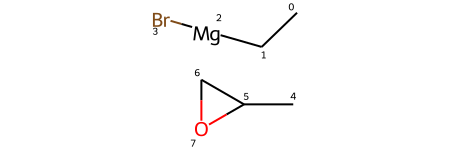

In [69]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True
new_mols[4]

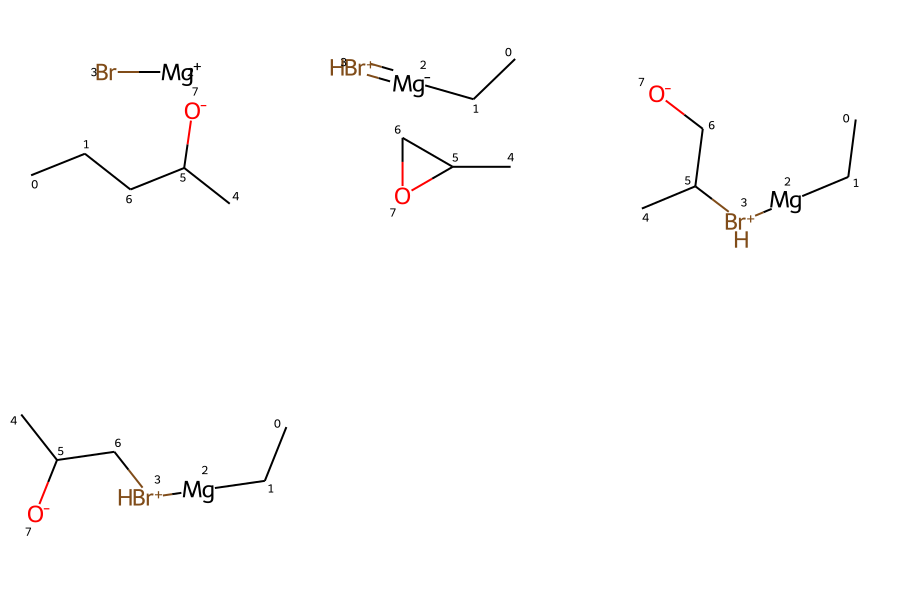

In [14]:
Chem.Draw.MolsToGridImage(connected_mols, molsPerRow=3, subImgSize=(300, 300))


In [117]:
for mol in connected_mols:
    print(Chem.MolToSmiles(mol))

C=CC.[O-]C1(c2ccccc2)O[OH+]1
[CH2-]C(C)[OH+]OC(=O)c1ccccc1
C[CH-]C[OH+]OC(=O)c1ccccc1
C=CC.[O-]C(=[O+]O)c1ccccc1
C[CH-]C[O+](O)C(=O)c1ccccc1
C=CC.[OH-].c1ccc(C2=[O+]O2)cc1
[CH2-]C(C)[O+]=C(OO)c1ccccc1
C[CH-]C[O+]=C(OO)c1ccccc1
O=C([O-])c1ccccc1.[CH2+]C(C)O
[CH2+]C(C)C([O-])(OO)c1ccccc1
C[CH+]CO.O=C([O-])c1ccccc1
C[CH+]COC(=O)c1ccccc1.[OH-]


In [28]:
Chem.MolToSmiles(connected_mols[0])

'[Br-].[CH2+]C(C)Br'

In [37]:
def write_reaction_smiles(mol1, mol2, product):
    with open ("reactions.txt", 'a', encoding='utf-8') as file:
        line = Chem.MolToSmiles(mol1) + "." + Chem.MolToSmiles(mol2) + ">>" + Chem.MolToSmiles(product)
        file.write(line +"\n")
    

In [111]:
for product in connected_mols:
    write_reaction_smiles(mol1, mol2, product)

In [17]:
Chem.MolToSmiles(inter_mol)

'C=C.[Br-].[BrH2+]'